HD 160691: Joint fit with RVs and mock Gaia DR4 astrometry

We first fit the 4 planet system using measured radial velocities.
We then simulate Gaia DR4 observations and fit them jointly
with the RVs to test how well the mock astrometry recovers the injected
orbital inclinations and nodes.

## 1. Load and inspect the radial velocities

We fit 487 binned radial velocity measurements of **μ Ara (HD 160691)**
compiled from published observations across seven instrument datasets.
Epochs are converted to MJD, and velocities and uncertainties to km/s.
The preview subtracts each instrument’s median velocity for display only.

We initialize the walkers near the orbital solution from
[Laliotis et al. (2023)](https://doi.org/10.3847/1538-3881/acc067),
while keeping the priors broad. Orange lines in the corner plots show
their published values for comparison.

We label the planets **b, d, e, c**, corresponding to periods of approximately
645, 9.64, 308, and 4035 days. This lettering differs from the paper.

In [1]:
from pathlib import Path
from time import perf_counter
from copy import deepcopy

import matplotlib.pyplot as plt
import numpy as np
from astropy.table import Table

import orbitize
from orbitize import gaia, plot, priors, read_input, sampler, system
from orbitize import simulate_dr4 as dr4_sim

np.random.seed(42)
rng = np.random.default_rng(42)
plt.style.use("default")

In [2]:
raw = Table.read(
    Path(orbitize.DATADIR) / "mu_ara_rv.csv",
    format="ascii.csv",
)

data_table = read_input.read_file(Table({
    "epoch": raw["time"] - 2_400_000.5,
    "object": np.zeros(len(raw), dtype=int),
    "rv": raw["mnvel"] / 1000,
    "rv_err": raw["errvel"] / 1000,
    "instrument": raw["tel"],
}))
data_table.sort("epoch")

print(f"{len(data_table)} RV measurements")
data_table[:5]

487 RV measurements


epoch,object,quant1,quant1_err,quant2,quant2_err,quant12_corr,quant_type,instrument
float64,int64,float64,float64,float64,float64,float64,bytes5,str20
50914.79348911485,0,-0.008572911859118978,0.002050898192989339,nan,nan,nan,rv,ucles
51118.38561618887,0,0.00993260997736739,0.0010574170926256436,nan,nan,nan,rv,ucles
51119.40004272573,0,0.006599320442644343,0.0009328262914934966,nan,nan,nan,rv,ucles
51120.38474146882,0,0.008898562492101606,0.0009324218271757462,nan,nan,nan,rv,ucles
51121.39081129525,0,0.008153093915705867,0.0009333222752048949,nan,nan,nan,rv,ucles


## 2. Set up the four-planet RV fit

We use Gaussian priors for the host star’s mass and parallax, adopting
the values reported by
[Laliotis et al. (2023)](https://doi.org/10.3847/1538-3881/acc067):

- **Stellar mass:** $1.15 \pm 0.035\,M_\odot$, adopted from
  Ramírez et al. (2012) in their RV sensitivity table.
- **Parallax:** $64.0853 \pm 0.0904$ mas, from Gaia EDR3,
  quoted in their discussion of HD 160691.

The orbital priors remain broad. Published orbital parameters are used
to initialize the sampler and provide comparison markers in the plots.

In [3]:
my_system = system.System(
    4, data_table,
    stellar_or_system_mass=1.15,
    plx=64.0853,
    mass_err=0.035,
    plx_err=0.0904,
    fit_secondary_mass=True,
    fitting_basis="SemiAmp",
    tau_ref_epoch=58849,
)
idx = my_system.param_idx

for body in range(1, 5):
    for name, prior in {
        "per": priors.LogUniformPrior(1 / 365.25, 100_000 / 365.25),
        "ecc": priors.UniformPrior(0, 0.99),
        "K": priors.LogUniformPrior(1e-5, 1),
        "inc": priors.SinPrior(),
        "pan": priors.UniformPrior(0, 2 * np.pi),
        "aop": priors.UniformPrior(0, 2 * np.pi),
        "tau": priors.UniformPrior(0, 1),
    }.items():
        my_system.sys_priors[idx[f"{name}{body}"]] = prior

for instrument in my_system.rv_instruments:
    my_system.sys_priors[idx[f"gamma_{instrument}"]] = priors.UniformPrior(
        -50, 50
    )
    my_system.sys_priors[idx[f"sigma_{instrument}"]] = priors.UniformPrior(
        0, 0.2
    )

## 3. Initialize the RV sampler

We initialize each planet’s period, eccentricity, and RV semi-amplitude
near the values reported by
[Laliotis et al. (2023)](https://doi.org/10.3847/1538-3881/acc067),
with a small spread between walkers.

Inclination, longitude of the ascending node, argument of periastron,
and orbital phase start from their broad priors.

In [4]:
num_walkers = 128
burn_steps = 100
num_steps = 500
thin = 1

laliotis_fit = {
    1: [644.93 / 365.25, 0.0499, 0.0357],
    2: [9.6394 / 365.25, 0.132, 0.0028],
    3: [308.4 / 365.25, 0.074, 0.0127],
    4: [4035.0 / 365.25, 0.026, 0.02225],
}

m = sampler.MCMC(
    my_system, num_temps=10, num_walkers=num_walkers, num_threads=10
)
sidx = m.sampled_param_idx
shape = m.curr_pos.shape[:-1]

for body, values in laliotis_fit.items():
    spreads = [values[0] * 1e-4, 0.005, values[2] * 0.05]
    for name, center, spread in zip(("per", "ecc", "K"), values, spreads):
        m.curr_pos[..., sidx[f"{name}{body}"]] = rng.uniform(
            center - spread, center + spread, size=shape
        )

for instrument in my_system.rv_instruments:
    use = data_table["instrument"] == instrument
    center = np.median(data_table["quant1"][use])
    m.curr_pos[..., sidx[f"gamma_{instrument}"]] = rng.normal(
        center, 0.005, size=shape
    )
    m.curr_pos[..., sidx[f"sigma_{instrument}"]] = rng.uniform(
        0.001, 0.01, size=shape
    )

m.check_prior_support()

## 4. Run the RV only fit

We now run the initialized sampler, discarding the burn-in and retaining
the production samples.

In [5]:
start = perf_counter()

run = m.run_sampler(
    num_walkers * num_steps,
    burn_steps=burn_steps,
    thin=thin,
)
rv_post = m.results.post

print(f"RV run took {(perf_counter() - start) / 60:.1f} minutes")
print(f"Posterior samples: {len(rv_post):,}")
print(f"Cold-chain acceptance: {run.acceptance_fraction[0].mean():.3f}")

Starting Burn in


/private/tmp/orbitize-463-stack/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/private/tmp/orbitize-463-stack/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/private/tmp/orbitize-463-stack/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/private/tmp/orbitize-463-stack/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/private/tmp/orbitize-463-stack/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/private/tmp/orbitize-463-stack/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/private/tmp/orbitize-463-st

100/100 steps of burn-in complete
Burn in complete. Sampling posterior now.


/private/tmp/orbitize-463-stack/orbitize/basis.py:914: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  comp_mass = fsolve(self.func, x0=1e-3, args=(lhs[orbit], m0[orbit]))


500/500 steps completed
Run complete
RV run took 3.6 minutes
Posterior samples: 64,000
Cold-chain acceptance: 0.201


## 5. Compare with the published RV solution

We plot the RV posterior for each planet in the order **b, d, e, c**.
Orange lines show the parameters
reported by [Laliotis et al. (2023)](https://doi.org/10.3847/1538-3881/acc067),
matched to our planet labels by orbital period.

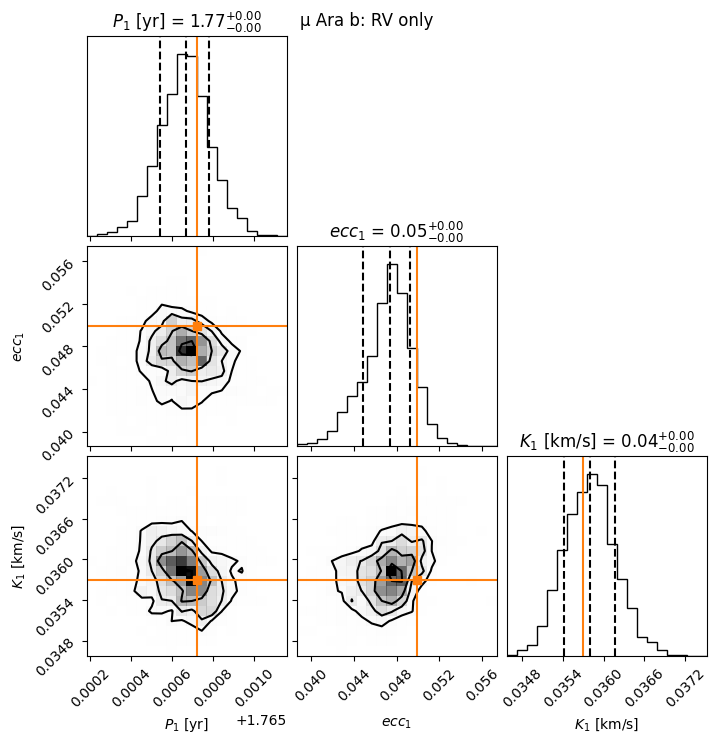

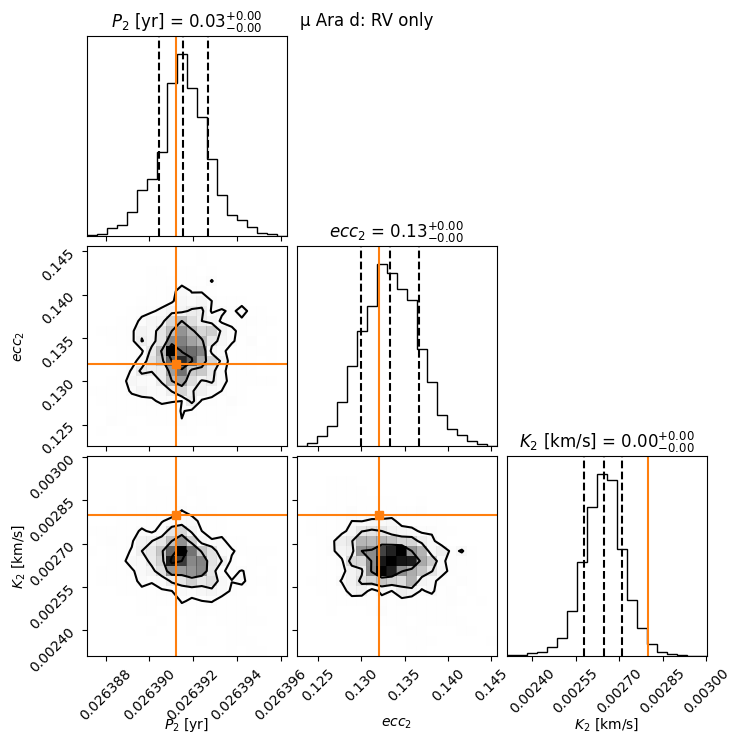

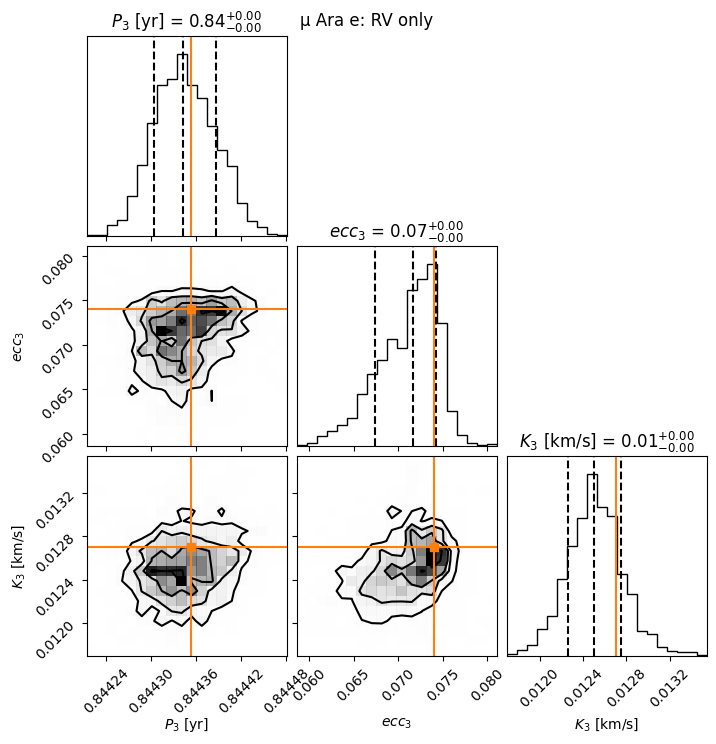

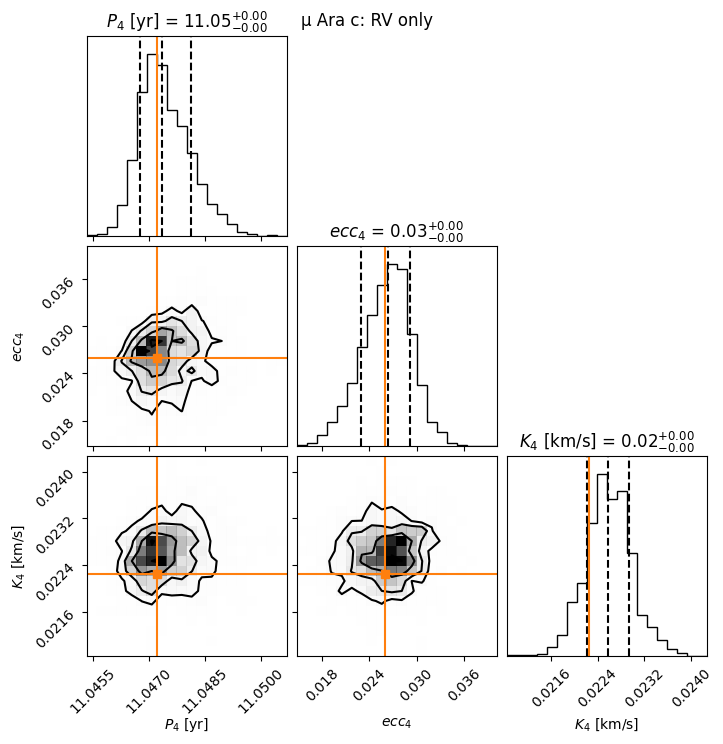

In [6]:
for body, planet in enumerate(("b", "d", "e", "c"), start=1):
    fig = plot.plot_corner(
        m.results,
        param_list=[f"{name}{body}" for name in ("per", "ecc", "K")],
        plot_priors=False,
        truths=laliotis_fit[body],
        truth_color="tab:orange",
        downsample=min(20_000, len(m.results.post)),
        quantiles=[0.16, 0.5, 0.84],
        show_titles=True,
        plot_datapoints=False,
    )
    fig.suptitle(f"μ Ara {planet}: RV only")
    plt.show()

## 6. Simulate Gaia DR4 astrometry

We take the highest likelihood RV sample and assign all four planets
a common inclination of $60^\circ$ and longitude of the ascending node
of $120^\circ$. These orientations are chosen for the simulation.

Using the GOST predictions in `mu_ara_gost_raw.csv`, the simulator
projects the star’s combined orbital reflex motion, position offsets,
proper motion, and parallax onto each scan direction. It adds Gaussian
noise using its uncertainty model at the star’s Gaia magnitude,
$G = 4.94$. The cell below reports the number of simulated transits
and their adopted uncertainty.


In [8]:
rv_system = m.system
rv_idx = rv_system.param_idx
bodies = range(1, rv_system.num_secondary_bodies + 1)

# Take the highest likelihood RV draw and inject a common orientation.
truth_fit = m.results.post[np.nanargmax(m.results.lnlike)].copy()
inc, lan = np.deg2rad([60.0, 120.0])

for body in bodies:
    truth_fit[rv_idx[f"inc{body}"]] = inc
    truth_fit[rv_idx[f"pan{body}"]] = lan

# Convert to the simulator's basis using the injected inclinations.
standard = rv_system.basis.to_standard_basis(truth_fit.copy())
standard_idx = rv_system.basis.standard_basis_idx
names = ["plx", "m0"] + [
    f"{name}{body}"
    for body in bodies
    for name in ("sma", "ecc", "inc", "aop", "pan", "tau", "m")
]
truth_params = {name: float(standard[standard_idx[name]]) for name in names}
truth_params.update(alpha0=0.0, delta0=0.0, pm_ra=-15.034, pm_dec=-190.901)

DR4_REF_EPOCH_MJD = dr4_sim.DR4_REF_EPOCH_MJD
gost_file = Path(orbitize.DATADIR) / "mu_ara_gost_raw.csv"

dr4_mock = dr4_sim.simulate_dr4(
    gost_file, truth_params,
    g_mag=4.942752,
    seed=160691,
    tau_ref_epoch=rv_system.tau_ref_epoch,
)

print(f"Simulated transits: {len(dr4_mock)}")
print(f"AL uncertainty: {dr4_mock['centroid_pos_error_al'][0]:.3f} mas")
dr4_mock[:5]

Simulated transits: 74
AL uncertainty: 0.125 mas


source_id,transit_id,obs_time_tcb,parallax_factor_al,parallax_factor_ac,scan_pos_angle,field_of_view,centroid_pos_al,centroid_pos_error_al,ra_offset_al,quant_al,sigma_al
,,d,,,rad,,mas,mas,,,
int64,int64,float64,float64,float64,float64,str4,float64,float64,float64,float64,float64
0,0,56906.20171300182,0.6883966469460991,0.7211775240623786,-0.8500294932226227,FoVP,366.92593412988623,0.12475569793288001,366.92593412988623,366.92593412988623,0.12475569793288001
0,1,56906.27571403794,0.6876111169772068,0.7222132518740163,-0.8481287836239148,FoVF,367.7100707701326,0.12475569793288001,367.7100707701326,367.7100707701326,0.12475569793288001
0,2,56941.33107358031,0.6417226053931399,0.7151074927032902,-0.5251610623943874,FoVP,469.9643342054188,0.12475569793288001,469.9643342054188,469.9643342054188,0.12475569793288001
0,3,56941.40507466439,0.6429943283663155,0.7134780208706066,-0.5265984857610458,FoVF,469.6809899634371,0.12475569793288001,469.6809899634371,469.6809899634371,0.12475569793288001
0,4,57082.476959182415,-0.6592544434281691,0.7025423356548718,-2.500750022441162,FoVF,-420.5344885753745,0.12475569793288001,-420.5344885753745,-420.5344885753745,0.12475569793288001


## 7. Set up the joint RV and Gaia fit

We retain the RV data and priors and add the mock Gaia along-scan
measurements. An additional Gaia jitter term has a uniform prior from
0 to 5 mas and is added in quadrature to the reported uncertainties.

We initialize the shared RV parameters using draws from the RV-only
posterior. Inclination, longitude of the ascending node, and Gaia
jitter start from their broad priors. For each starting orbit, we
estimate the position offsets and proper motion from the Gaia data.

These choices set the walkers’ starting positions but all parameters remain broad in the fit.

In [9]:
from copy import deepcopy

rv_sys = m.system
dr4 = gaia.DR4LogProb(
    0, dr4_mock,
    ref_epoch_mjd=dr4_sim.DR4_REF_EPOCH_MJD,
    jitter_prior=priors.UniformPrior(0, 5),
)
joint_system = system.System(
    rv_sys.num_secondary_bodies, rv_sys.data_table.copy(),
    rv_sys.stellar_or_system_mass, rv_sys.plx,
    mass_err=rv_sys.mass_err, plx_err=rv_sys.plx_err,
    fit_secondary_mass=True, fitting_basis=rv_sys.fitting_basis,
    tau_ref_epoch=rv_sys.tau_ref_epoch,
    restrict_angle_ranges=rv_sys.restrict_angle_ranges,
    gaia=dr4,
)
jidx = joint_system.param_idx
for name, col in rv_sys.param_idx.items():
    joint_system.sys_priors[jidx[name]] = deepcopy(rv_sys.sys_priors[col])

joint_mcmc = sampler.MCMC(
    joint_system, num_temps=m.num_temps,
    num_walkers=m.num_walkers, num_threads=m.num_threads,
)
sidx = joint_mcmc.sampled_param_idx
pos = joint_mcmc.curr_pos.reshape(-1, joint_mcmc.num_params).copy()

shared = [
    name for name in sidx
    if name in rv_sys.param_idx and not name.startswith(("inc", "pan"))
]
rows = rng.integers(len(m.results.post), size=len(pos))
pos[:, [sidx[name] for name in shared]] = m.results.post[rows][
    :, [rv_sys.param_idx[name] for name in shared]
]

full = joint_mcmc._fill_in_fixed_params(pos)
ra, dec, _, _ = joint_system.compute_all_orbits(
    full.T, epochs=dr4.epochs_mjd, params_basis="fitting",
)
linear_columns = [
    sidx[name] for name in ("alpha0", "delta0", "pm_ra", "pm_dec")
]
for walker, params in enumerate(full):
    pos[walker, linear_columns] = dr4.guess_initial_astrometry(
        ra[:, 0, walker], dec[:, 0, walker],
        params[jidx["plx"]], params[jidx["dr4_jitter"]],
    )

joint_mcmc.curr_pos = pos.reshape(joint_mcmc.curr_pos.shape)
joint_mcmc.check_prior_support()
print("Joint walkers initialized.")

Joint walkers initialized.


In [10]:
start = perf_counter()

joint_run = joint_mcmc.run_sampler(
    joint_mcmc.num_walkers * num_steps,
    burn_steps=burn_steps,
    thin=thin,
)
joint_results = joint_mcmc.results

print(f"Joint run took {(perf_counter() - start) / 60:.1f} minutes")
print(f"Cold-chain acceptance: {joint_run.acceptance_fraction[0].mean():.3f}")
print(f"Best log-likelihood: {np.nanmax(joint_results.lnlike):.3f}")

Starting Burn in


/private/tmp/orbitize-463-stack/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/private/tmp/orbitize-463-stack/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/private/tmp/orbitize-463-stack/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/private/tmp/orbitize-463-stack/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/private/tmp/orbitize-463-stack/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/private/tmp/orbitize-463-stack/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/private/tmp/orbitize-463-st

100/100 steps of burn-in complete
Burn in complete. Sampling posterior now.
500/500 steps completed
Run complete
Joint run took 5.7 minutes
Cold-chain acceptance: 0.149
Best log-likelihood: 2111.516


## 8. Compare the joint posteriors with the injected orbit

We plot each planet’s period, eccentricity, inclination, longitude
of the ascending node (LAN), and RV semi-amplitude, in the order
**b, d, e, c**. The shared Gaia jitter appears in all four plots.

Orange lines mark the simulation inputs, including the common
inclination of $60^\circ$, LAN of $120^\circ$.

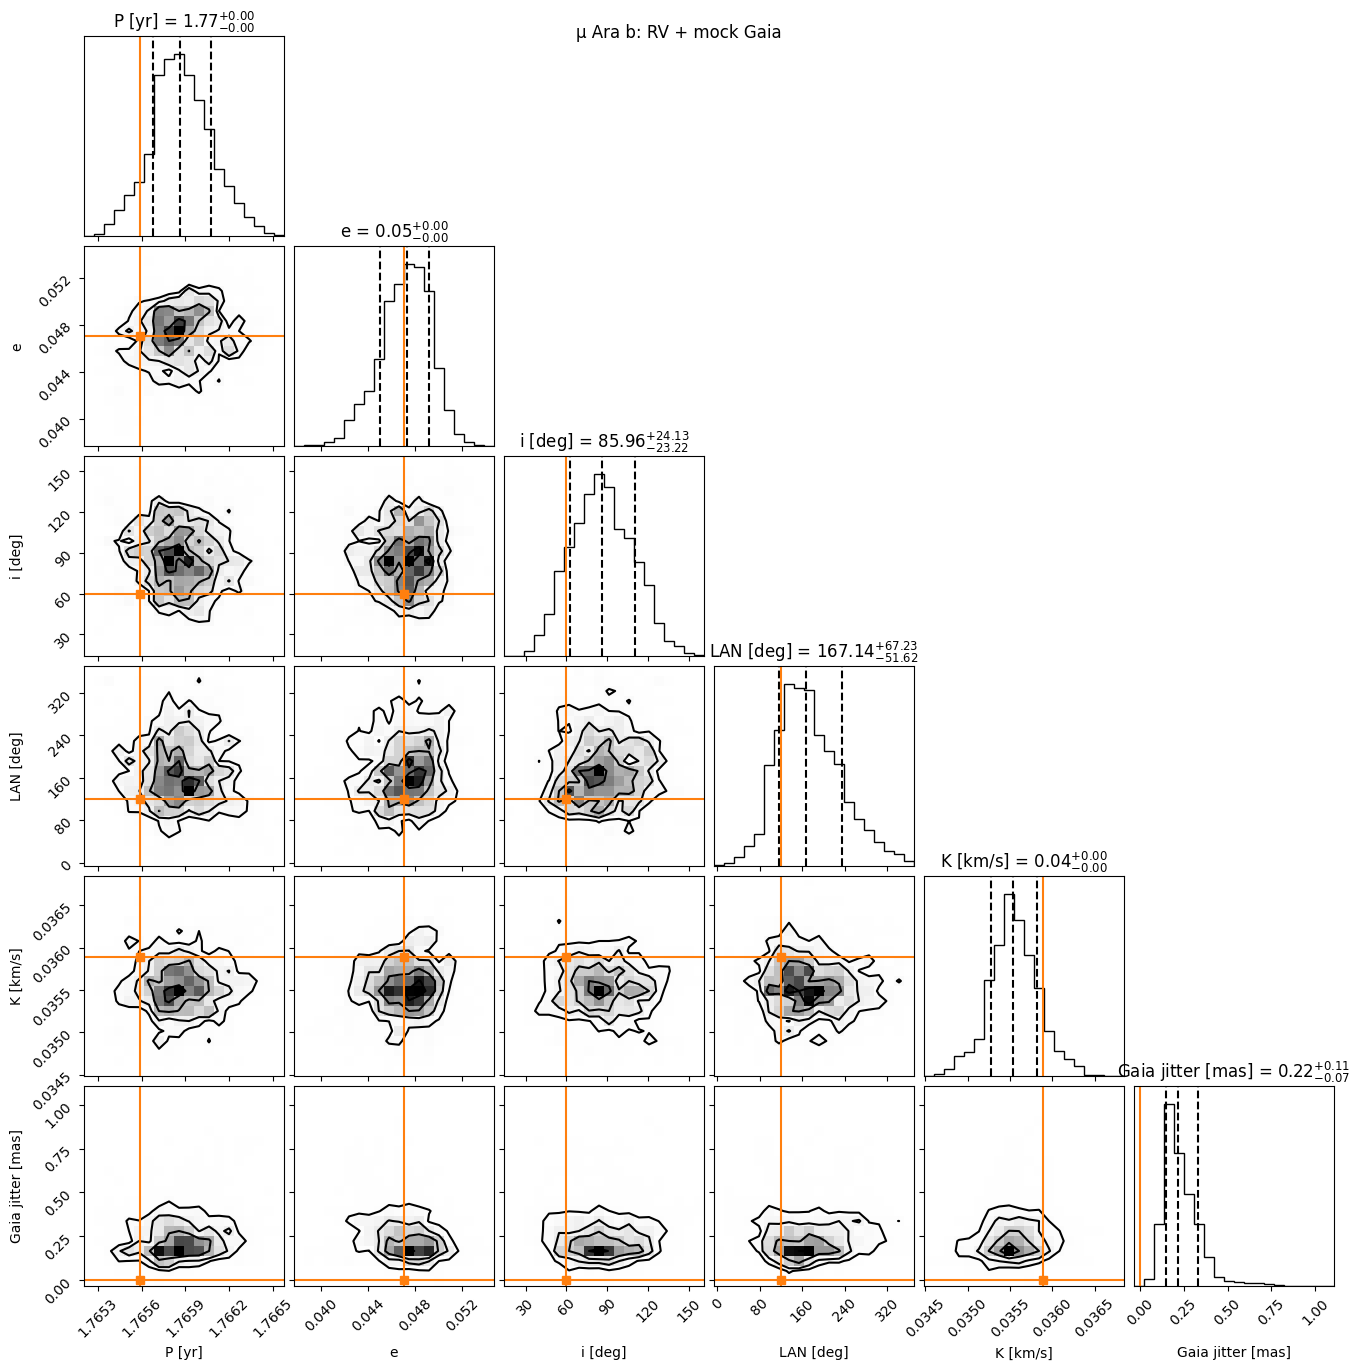

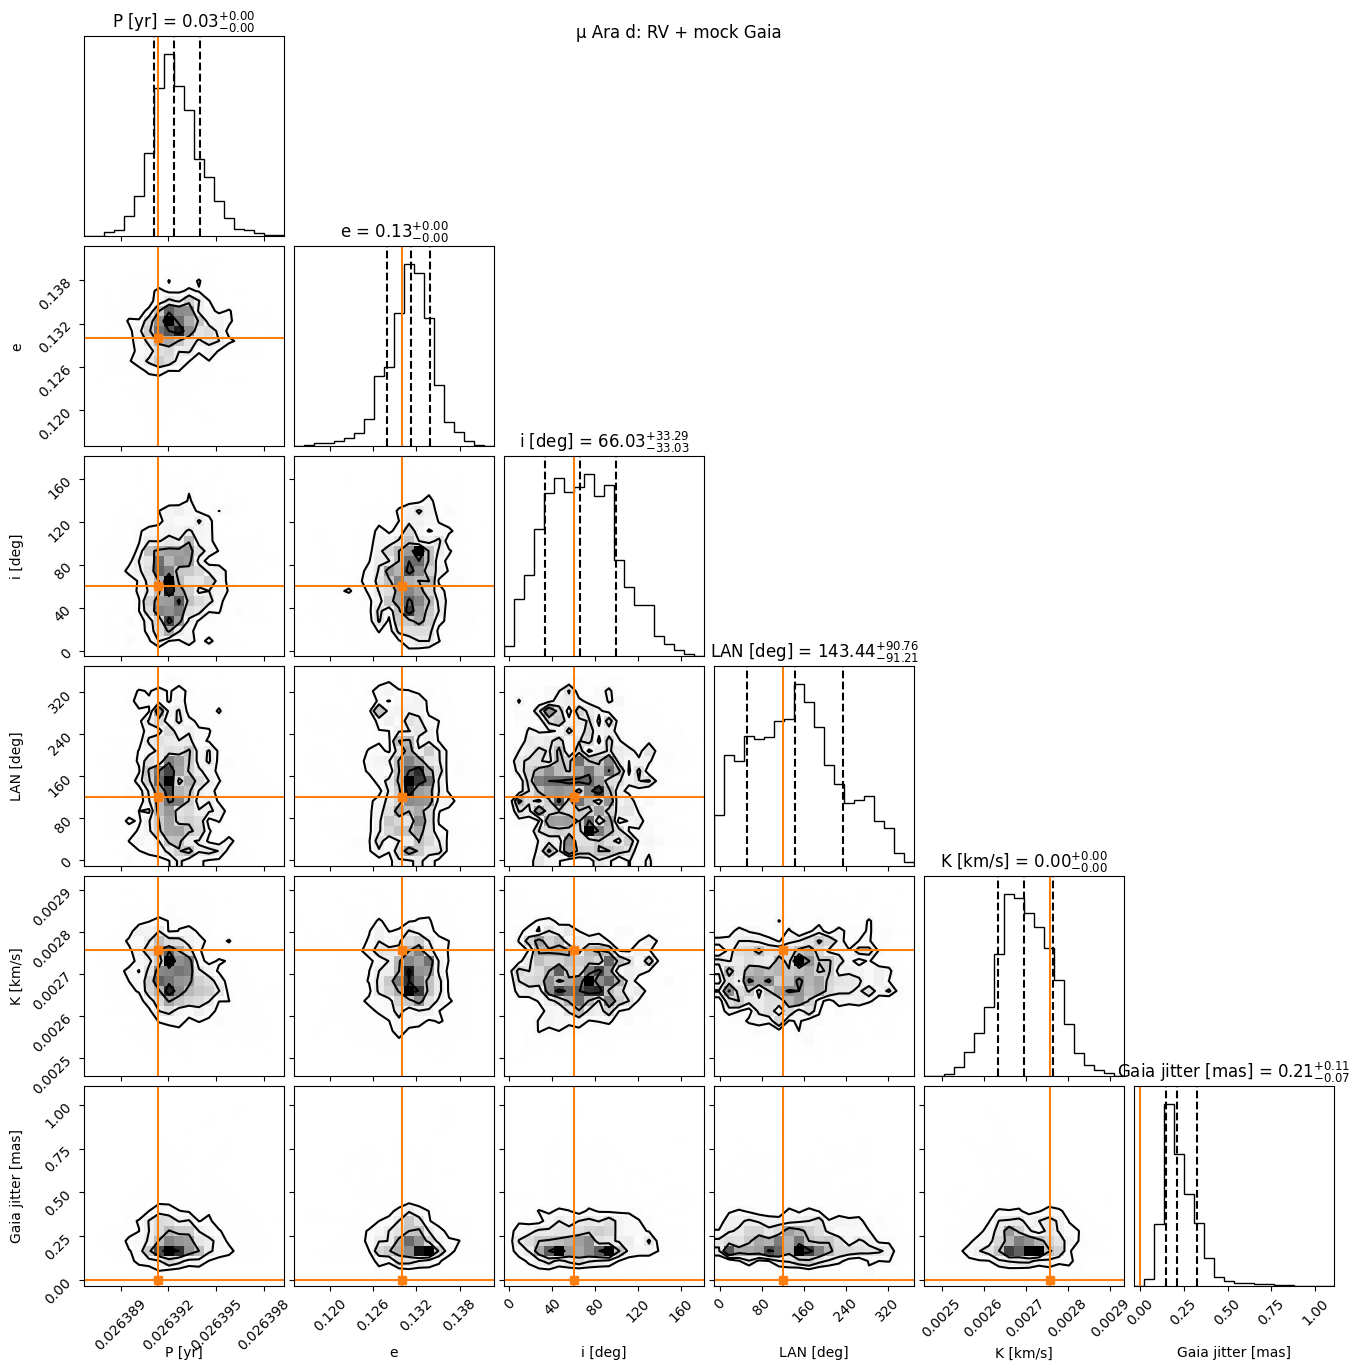

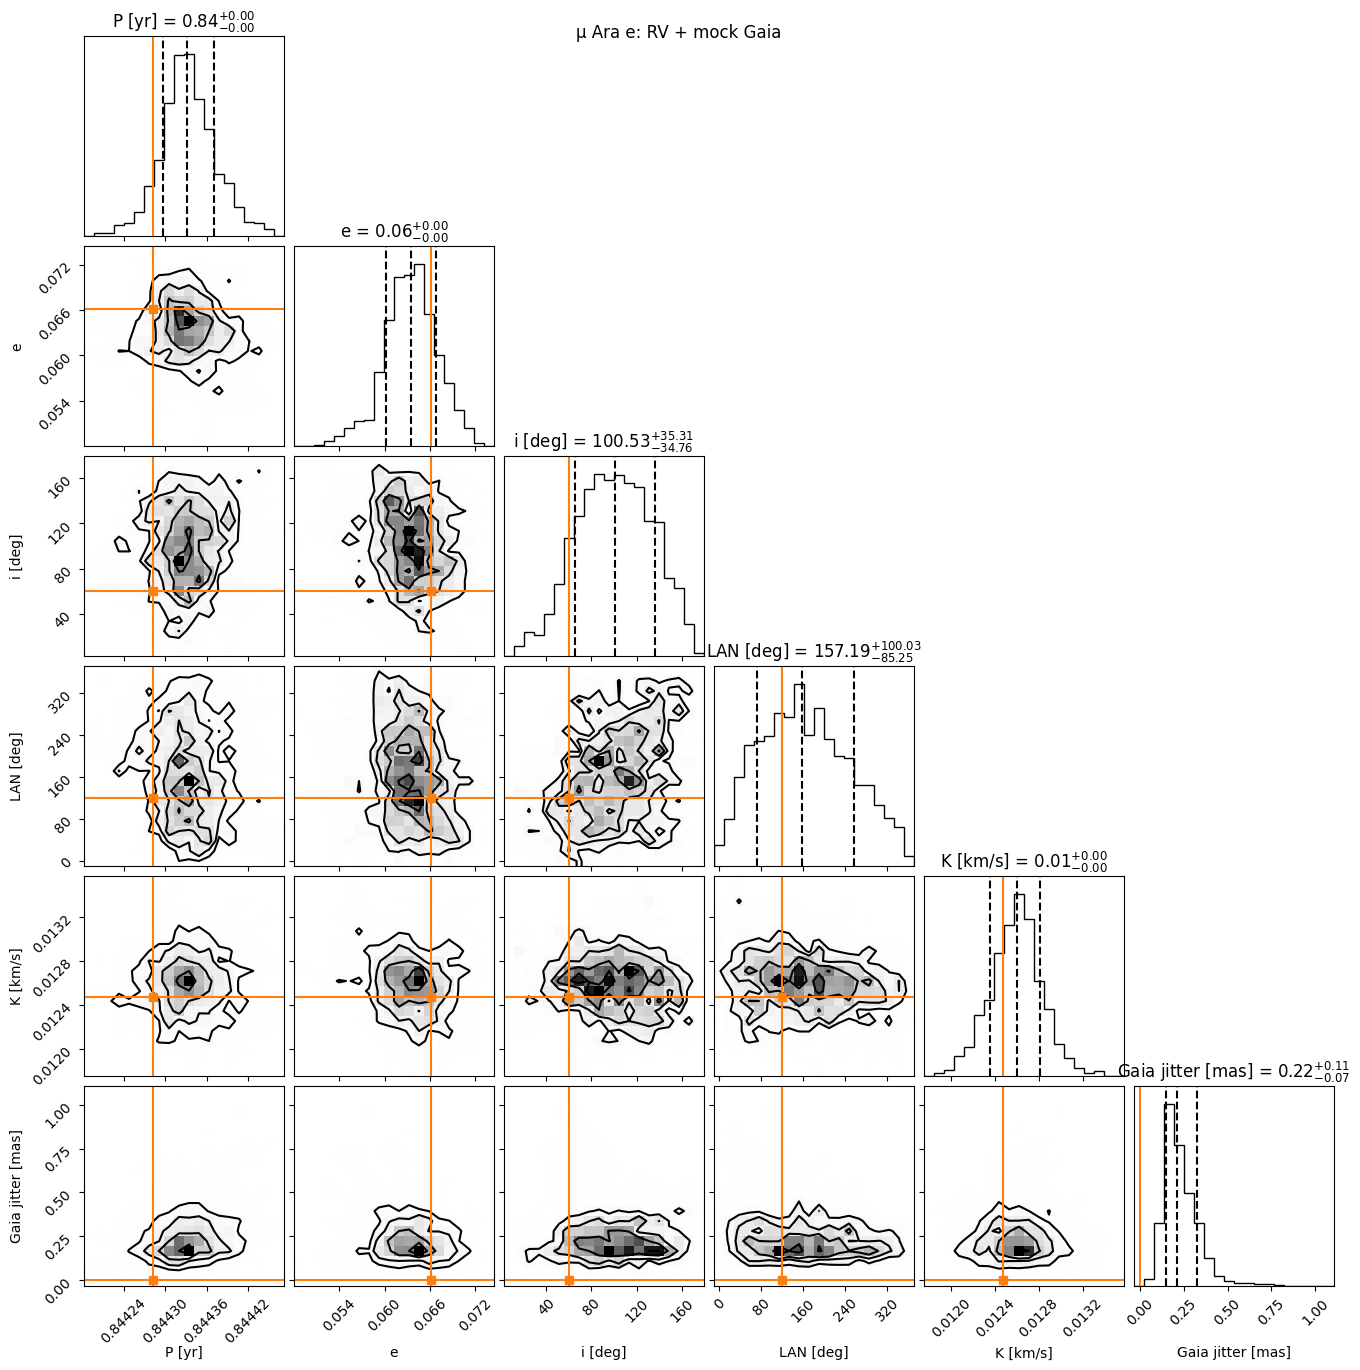

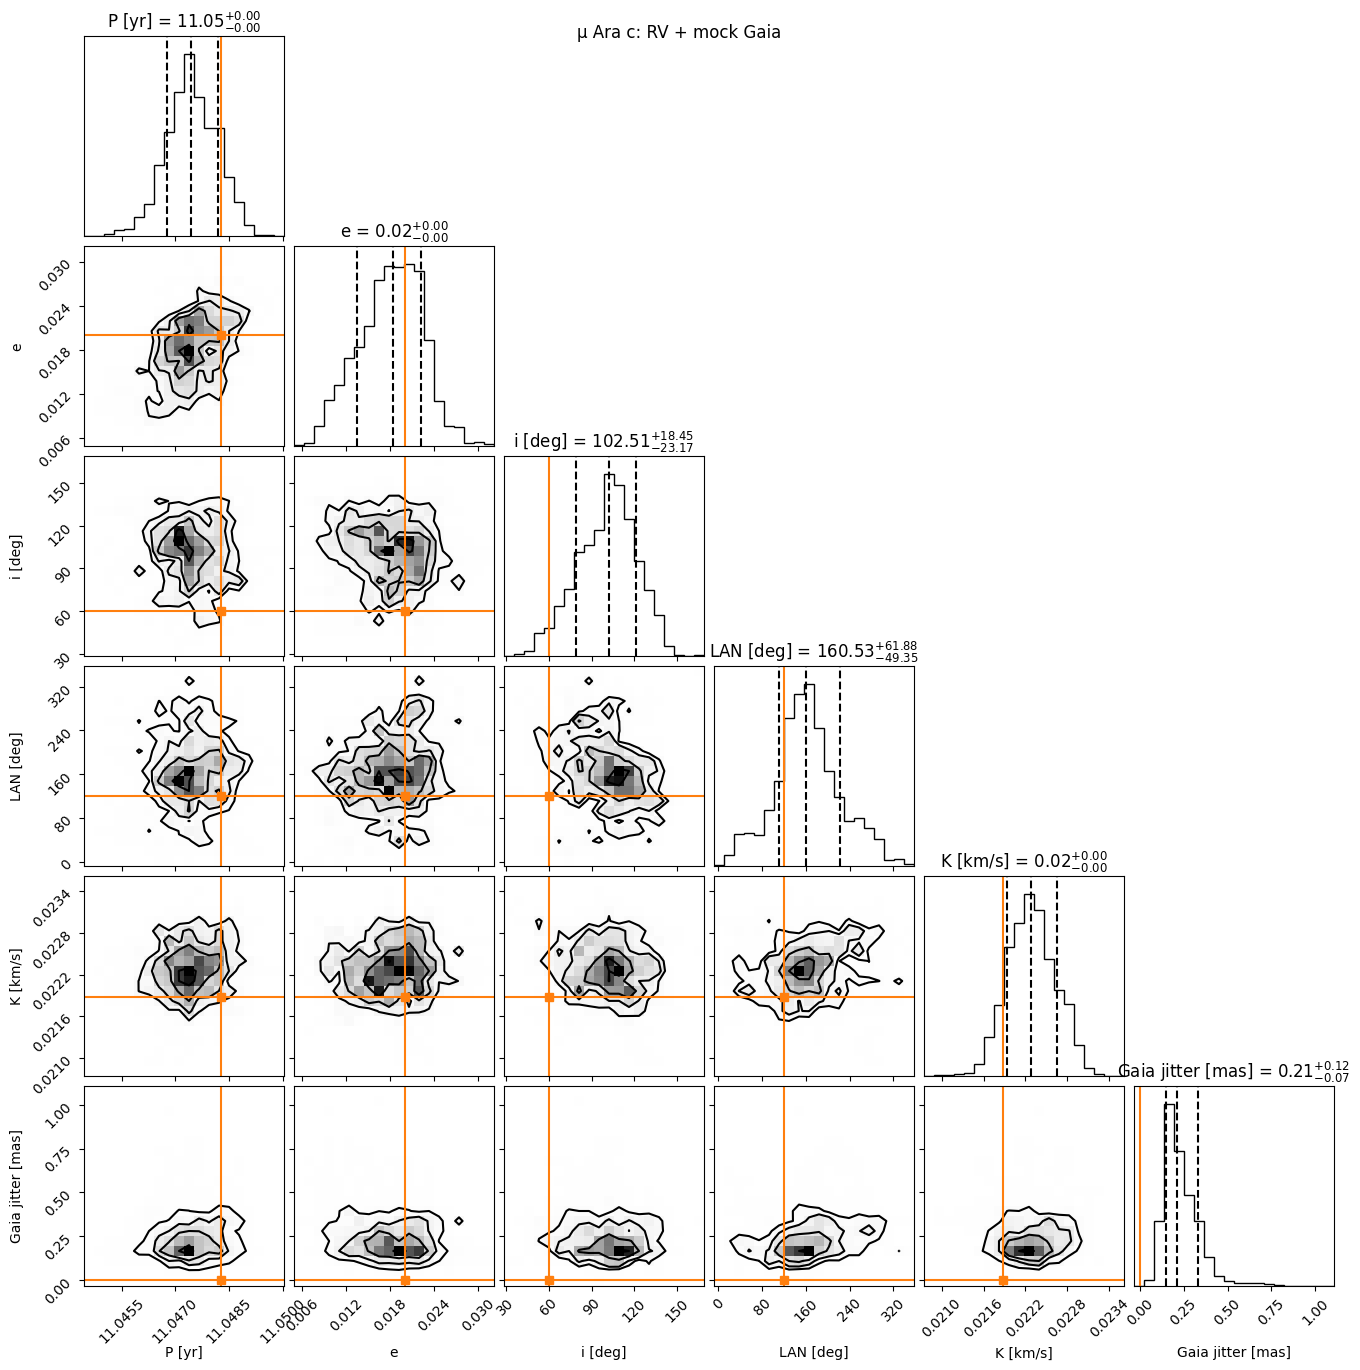

In [11]:
joint_results = joint_mcmc.results
rv_idx = m.system.param_idx

for body, planet in enumerate(("b", "d", "e", "c"), start=1):
    names = [f"{p}{body}" for p in ("per", "ecc", "inc", "pan", "K")]
    truths = [truth_fit[rv_idx[name]] for name in names] + [0.0]
    truths[2:4] = np.rad2deg(truths[2:4])
    names += ["dr4_jitter"]

    samples = joint_results.post[
        :, [joint_results.param_idx[name] for name in names]
    ].copy()
    samples[:, 2:4] = np.rad2deg(samples[:, 2:4])
    lo = np.minimum(samples.min(axis=0), truths)
    hi = np.maximum(samples.max(axis=0), truths)
    pad = 0.03 * (hi - lo)

    fig = plot.plot_corner(
        joint_results,
        param_list=names,
        labels=["P [yr]", "e", "i [deg]", "LAN [deg]",
                "K [km/s]", "Gaia jitter [mas]"],
        truths=truths,
        truth_color="tab:orange",
        range=list(zip(lo - pad, hi + pad)),
        plot_priors=False,
        downsample=min(20_000, len(joint_results.post)),
        quantiles=[0.16, 0.5, 0.84],
        show_titles=True,
        plot_datapoints=False,
    )
    fig.suptitle(f"μ Ara {planet}: RV + mock Gaia")
    plt.show()

Now, let's plot the orbit on sky:

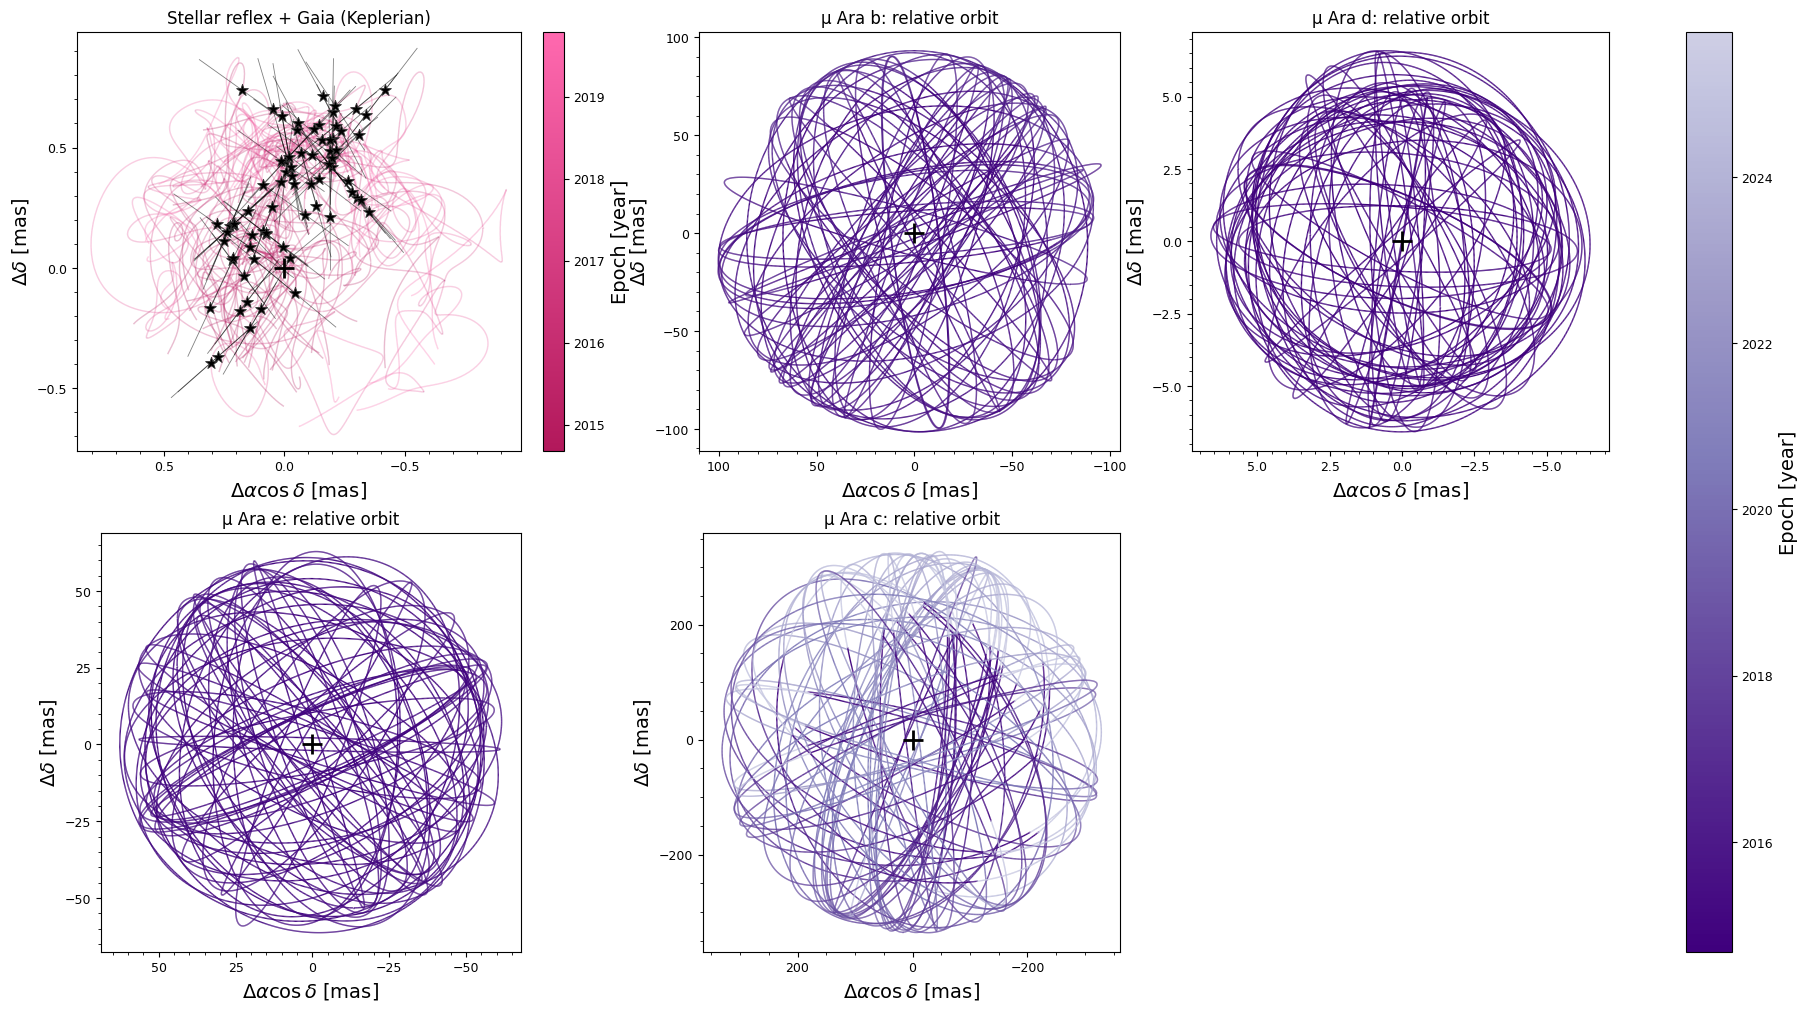

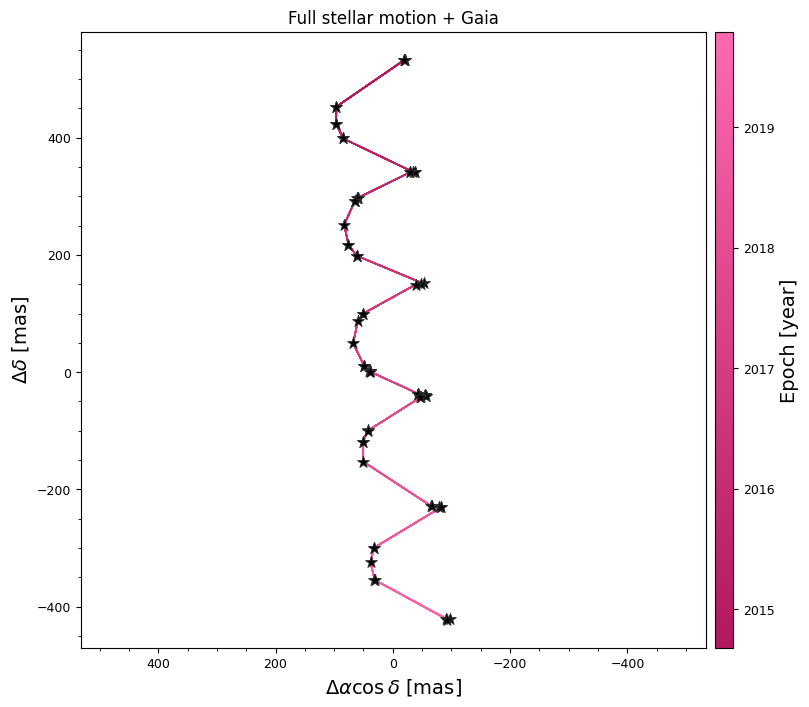

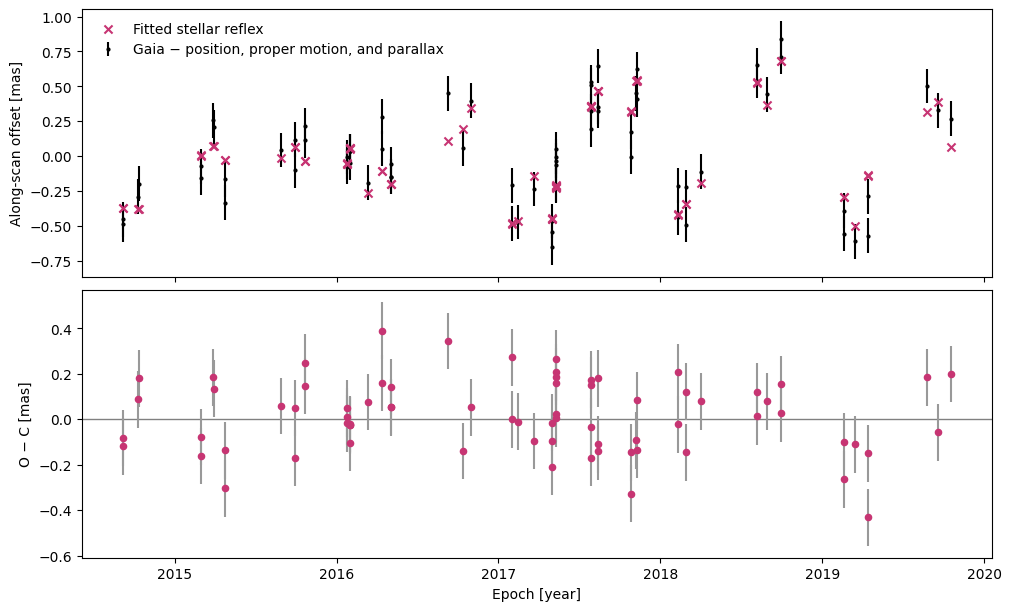

In [14]:
options = dict(
    num_orbits_to_plot=50,
    num_epochs_to_plot=1_000,
    include_jitter=True,
    fontsize=14,
)

fig = plot.Plotter.plot_dr4_orbit(
    joint_results, joint_system,
    mode="keplerian",
    include_planet=True,
    planet_to_plot=[1, 2, 3, 4],
    **options,
)
for ax, planet in zip(fig.axes[1:5], ("b", "d", "e", "c")):
    ax.set_title(f"μ Ara {planet}: relative orbit")

full_fig = plot.Plotter.plot_dr4_orbit(
    joint_results, joint_system, mode="full_motion", **options,
)

residual_fig = plot.Plotter.plot_dr4_al_residuals(joint_results)

Let's save the posteriors!

In [15]:
joint_mcmc.results.save_results("HD160691_joint_results.hdf5")

And plot them on sky:

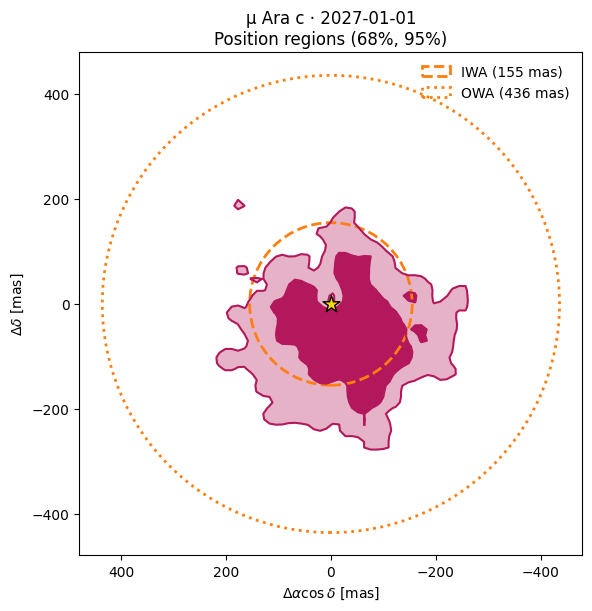

In [19]:

fig = plot.Plotter.plot_planet_position(
    joint_mcmc.results,
    date="2027-01-01",
    object_to_plot=4,
    name="μ Ara c",
    iwa=155,
    owa=436,
)